# Hyperparameter sweep of the ffNN (xview_recognition)

Auxiliary notebook of the assignment: it shows the results of the experiment sweeps that led to the final ffNN of
`ffNN_example.ipynb`. The runs are executed by `sweep.py` (one function per phase), each one through
`experiment_utils.run_experiment`, and logged to `experiments/experiments.csv` and `experiments/history/<id>.json`.
This notebook only reads those files and draws the figures (saved in `experiments/plots/`).

- **Main metric:** mean recall (macro) on the validation split, because the classes are strongly imbalanced
  (Building 3 594 images vs Helipad 111). Secondary: accuracy, validation loss, per-class recall.
- **Validation split:** 10 % stratified by class (`random_state=1`), seed 1 everywhere. The test set is never used to decide.
- **Reading the capacity plots:** train (dashed) and validation (solid) low and close → underfitting;
  train high and validation clearly lower → overfitting; both high and close → good fit.
- The reasoning and the references behind each decision are in `LOGBOOK.md` (IDs `EXP-###`).

In [1]:
import pandas as pd
from IPython.display import display
import plot_utils as pu

pd.set_option('display.max_colwidth', 60)
COLS = ['id', 'change', 'params', 'actual_epochs', 'best_epoch', 'train_acc', 'val_acc', 'train_mean_recall', 'mean_recall', 'min_recall', 'val_loss', 's_per_epoch']
def table(df):
    display(df[COLS].style.format(precision=3).hide(axis='index'))

I0000 00:00:1791021003.024473  250656 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791021004.286206  250656 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Phase 0: baseline and reproducibility (EXP-001)

The assignment's model (`Flatten → ReLU → Dense(13) → softmax` on raw pixels in [0, 255]), with seed 1 and the new
stratified split. It is the reference for every later phase.

id,change,params,actual_epochs,best_epoch,train_acc,val_acc,train_mean_recall,mean_recall,min_recall,val_loss,s_per_epoch
EXP-001,"baseline (seed 1, stratified split)",1956877,20,12,0.438,0.389,0.345,0.282,0.000,9.829,14.500


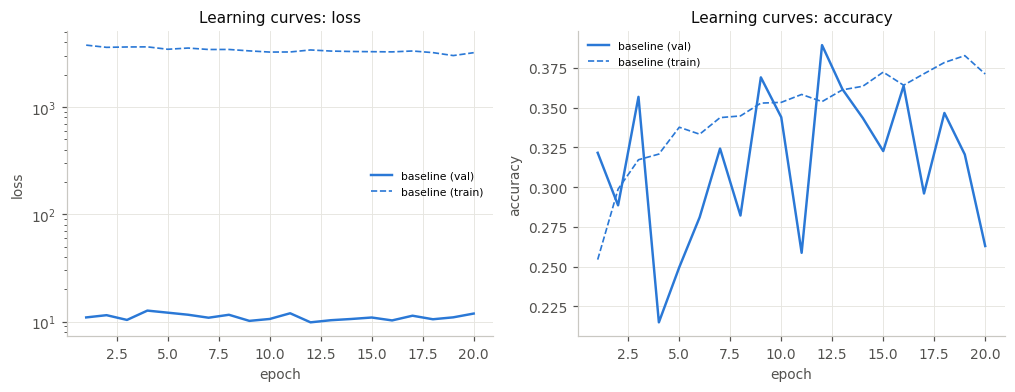

In [2]:
table(pu.load_results(phase=0))
fig, axes = pu.plt.subplots(1, 2, figsize=(11, 3.6))
pu.plot_learning_curves(['EXP-001'], 'loss', labels=['baseline'], ax=axes[0])
pu.plot_learning_curves(['EXP-001'], 'accuracy', labels=['baseline'], ax=axes[1], logy=False)
pu._save(fig, 'phase0_baseline_learning_curves');

**Interpretation.** The loss stays around 10³ for the whole run (a sensible value would be ≈ ln 13 ≈ 2.6) and the
validation accuracy jumps by several points from one epoch to the next: the softmax is saturated because the raw pixels make
the logits huge. Train and validation are both low and close → the model underfits, and the limit is the optimisation.
Two classes (Fishing vessel, Helipad) are never predicted. Baseline: **val acc 0.389, mean recall 0.282**.

## Phase 1: base fixes (EXP-002 → CHG-008 → EXP-003 → EXP-004)

Applied as a cumulative ladder, one change per step, each on top of the previous one:
`Rescaling(1/255)` (EXP-002) → remove the ReLU after `Flatten` and use `keras.Input` (CHG-008, must not change anything)
→ callbacks adapted to the run length: 60 epochs, EarlyStopping patience 10, ReduceLROnPlateau patience 4, comparing the
monitored metric (EXP-003) → per-channel standardisation instead of `/255` (EXP-004). The data cache and batched evaluation
(CHG-007) do not change the model.

id,change,params,actual_epochs,best_epoch,train_acc,val_acc,train_mean_recall,mean_recall,min_recall,val_loss,s_per_epoch
EXP-001,"baseline (seed 1, stratified split)",1956877,20,12,0.438,0.389,0.345,0.282,0.000,9.829,14.500
EXP-002,+ Rescaling(1/255),1956877,20,20,0.550,0.418,0.528,0.365,0.000,4.795,13.510
CHG-008,- ReLU after Flatten (no-op check),1956877,20,20,0.550,0.418,0.528,0.365,0.000,4.795,12.100
EXP-003_val_loss,"callbacks ES10/RLR4, 60 ep, monitor val_loss",1956877,60,50,0.576,0.410,0.564,0.365,0.182,2.688,13.680
EXP-003_val_accuracy,"callbacks ES10/RLR4, 60 ep, monitor val_accuracy",1956877,20,10,0.513,0.417,0.471,0.338,0.081,3.763,12.630
EXP-003_val_mean_recall,"callbacks ES10/RLR4, 60 ep, monitor val_mean_recall",1956877,34,24,0.560,0.413,0.548,0.382,0.199,2.823,12.730
EXP-004,per-channel standardisation (train mean/std),1956877,22,12,0.501,0.367,0.517,0.344,0.181,8.484,12.530


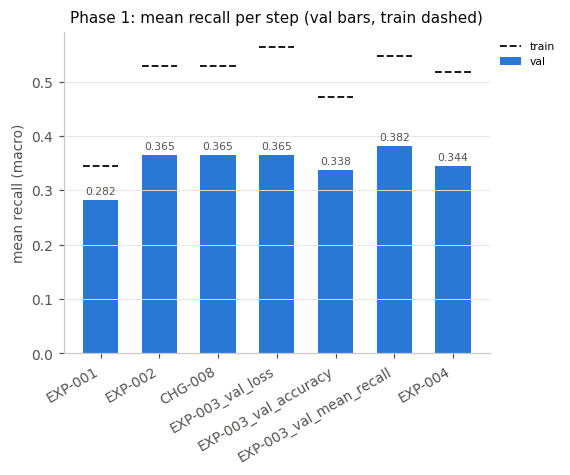

In [3]:
df1 = pu.load_results(phase=1)
table(pd.concat([pu.load_results(phase=0), df1]))
pu.plot_bars(pd.concat([pu.load_results(phase=0), df1]), 'mean_recall', name='phase1_mean_recall_by_step', title='Phase 1: mean recall per step (val bars, train dashed)');

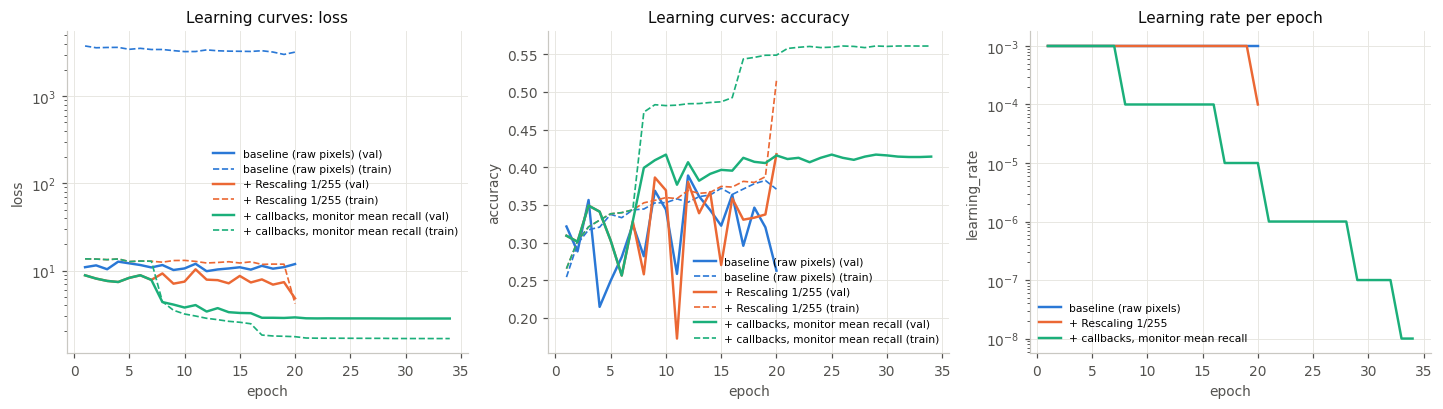

In [4]:
runs = ['EXP-001', 'EXP-002', 'EXP-003_val_mean_recall']
labels = ['baseline (raw pixels)', '+ Rescaling 1/255', '+ callbacks, monitor mean recall']
fig, axes = pu.plt.subplots(1, 3, figsize=(16, 3.8))
pu.plot_learning_curves(runs, 'loss', labels=labels, ax=axes[0])
pu.plot_learning_curves(runs, 'accuracy', labels=labels, ax=axes[1], logy=False)
pu.plot_learning_curves(runs, 'learning_rate', labels=labels, ax=axes[2], title='Learning rate per epoch')
pu._save(fig, 'phase1_learning_curves_baseline_vs_fixed');

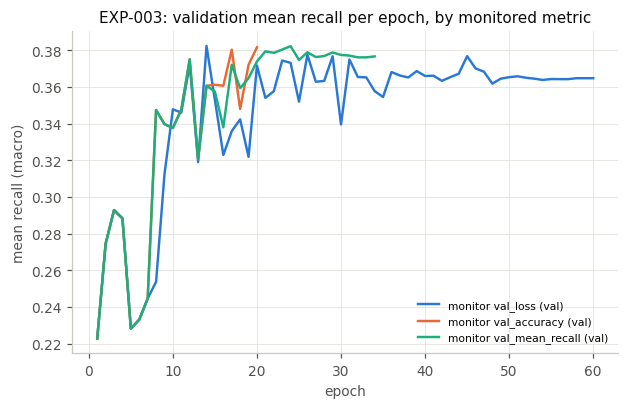

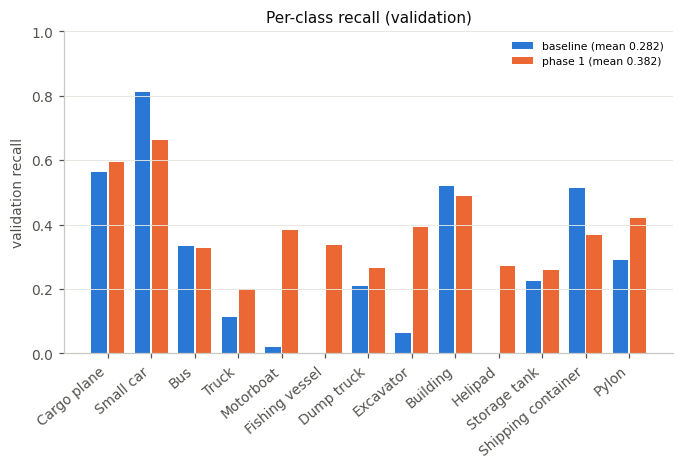

In [5]:
pu.plot_learning_curves(['EXP-003_val_loss', 'EXP-003_val_accuracy', 'EXP-003_val_mean_recall'], 'mean_recall',
                        labels=['monitor val_loss', 'monitor val_accuracy', 'monitor val_mean_recall'], logy=False,
                        name='phase1_monitor_comparison', title='EXP-003: validation mean recall per epoch, by monitored metric');
pu.plot_per_class_recall(['EXP-001', 'EXP-003_val_mean_recall'], labels=['baseline', 'phase 1'], name='phase1_per_class_recall');

**Interpretation.** Scaling the input to [0, 1] is the big change (+8.3 pp of mean recall) and reveals capacity to
fit: train accuracy rises above validation (0.55 vs 0.42). Removing the ReLU after `Flatten` gives exactly the same run,
as expected (ReLU is the identity on non-negative inputs). With callbacks that can actually fire, the learning rate drops
from 1e-3 to ≤ 1e-6, the validation curves stop oscillating, and no class stays at recall 0 any more (min recall ≈ 0.2).
Monitoring `val_accuracy` stops too early on a noisy peak; `val_mean_recall` gives the best mean recall (0.382) and is
also the decision metric, so it is kept. Per-channel standardisation is *worse* (0.344): with Adam at lr 1e-3 a larger
input magnitude makes each step move the logits more, so the softmax saturates harder (epoch-1 loss 60 vs 13.6). This
points to a learning rate that is too high for 150 528 inputs (phase 5).

| Step | Tried | mean recall | Kept for next phase |
|---|---|---|---|
| EXP-002 | `Rescaling(1/255)` | 0.282 → 0.365 | yes |
| CHG-008 | no ReLU after `Flatten`, `keras.Input` | 0.365 (identical) | yes |
| EXP-003 | 60 epochs, ES 10, RLR 4; monitor loss / acc / mean recall | 0.365 / 0.338 / **0.382** | monitor `val_mean_recall` |
| EXP-004 | per-channel standardisation | 0.344 | no, keep `/255` |

**Corrected baseline (end of phase 1): val acc 0.413, mean recall 0.382** (EXP-003_val_mean_recall).

## Phase 2: input resolution (EXP-005)

Same small MLP for every size (`Flatten → Dense(256, relu, he_normal) → Dense(13)`, the phase-1 setup otherwise), the
image downsampled by area averaging when it is cached. The best size at lr 1e-3 fell at the edge of the grid, so the grid
was extended to 8–24; and since train accuracy also fell with resolution (an optimisation effect, not only variance), a
small joint resolution × learning-rate grid compares each size at its own best lr.

In [6]:
df2 = pu.expand_config(pu.load_results('EXP-005'))
table(df2.sort_values(['lr', 'res']))
display(df2.pivot_table(index='lr', columns='res', values='mean_recall').style.format(precision=3, na_rep='').set_caption('validation mean recall (rows: lr, columns: resolution)'))

id,change,params,actual_epochs,best_epoch,train_acc,val_acc,train_mean_recall,mean_recall,min_recall,val_loss,s_per_epoch
EXP-005_r64_lr3e-5,"resolution 64x64, Dense(256), lr 3e-5",3149325,24,14,0.540,0.498,0.455,0.395,0.000,1.502,8.630
EXP-005_r16_lr1e-4,"resolution 16x16, Dense(256), lr 1e-4",200205,31,21,0.489,0.465,0.377,0.343,0.000,1.578,7.000
EXP-005_r32_lr1e-4,"resolution 32x32, Dense(256), lr 1e-4",790029,30,20,0.604,0.557,0.526,0.474,0.000,1.356,7.360
EXP-005_r64_lr1e-4,"resolution 64x64, Dense(256), lr 1e-4",3149325,30,20,0.641,0.577,0.579,0.510,0.091,1.330,8.630
EXP-005_r16_lr3e-4,"resolution 16x16, Dense(256), lr 3e-4",200205,34,24,0.612,0.574,0.543,0.511,0.182,1.333,6.970
EXP-005_r32_lr3e-4,"resolution 32x32, Dense(256), lr 3e-4",790029,30,20,0.646,0.580,0.592,0.524,0.182,1.276,7.240
EXP-005_r64_lr3e-4,"resolution 64x64, Dense(256), lr 3e-4",3149325,31,21,0.586,0.543,0.510,0.463,0.091,1.390,8.470
EXP-005_r8,"resolution 8x8, Dense(256)",52749,30,20,0.583,0.533,0.541,0.499,0.182,1.417,7.090
EXP-005_r16,"resolution 16x16, Dense(256)",200205,36,26,0.661,0.600,0.609,0.549,0.182,1.275,7.720
EXP-005_r24,"resolution 24x24, Dense(256)",445965,30,20,0.642,0.585,0.596,0.535,0.182,1.283,6.990


res,8,16,24,32,48,64,112,224
lr,,,,,,,,
0.000030,,,,,,0.395,,
0.000100,,0.343,,0.474,,0.510,,
0.000300,,0.511,,0.524,,0.463,,
0.001000,0.499,0.549,0.535,0.497,0.469,0.427,0.325,0.129
0.003000,,0.510,,,,,,


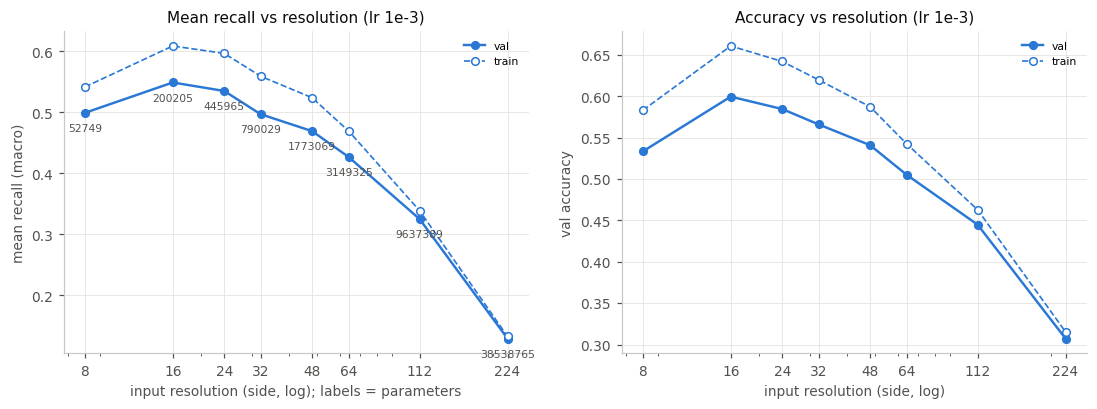

In [7]:
main = df2[df2['lr'] == 1e-3].copy()
main['inputs'] = main['res'] ** 2 * 3
fig, axes = pu.plt.subplots(1, 2, figsize=(12, 3.8))
pu.plot_sweep(main, 'res', 'mean_recall', logx=True, annotate='params', ax=axes[0], xlabel='input resolution (side, log); labels = parameters',
              title='Mean recall vs resolution (lr 1e-3)')
pu.plot_sweep(main, 'res', 'val_acc', logx=True, ax=axes[1], xlabel='input resolution (side, log)', title='Accuracy vs resolution (lr 1e-3)')
for ax in axes:
    ax.set_xticks(sorted(main['res'])); ax.set_xticklabels(sorted(main['res']))
pu._save(fig, 'phase2_metric_vs_resolution');

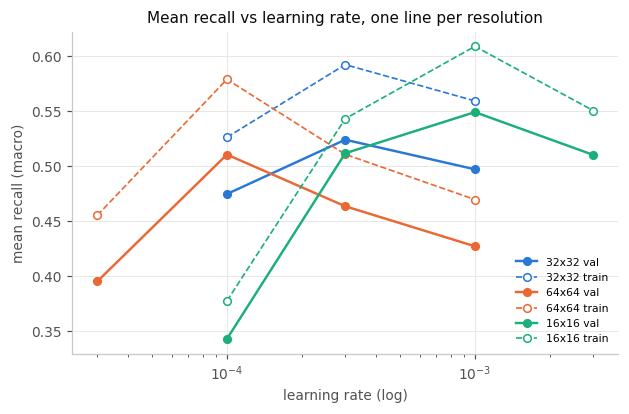

In [8]:
grid = df2[df2['res'].isin([16, 32, 64])].copy()
grid['resolution'] = grid['res'].astype(str) + 'x' + grid['res'].astype(str)
ax = pu.plot_sweep(grid, 'lr', 'mean_recall', logx=True, group='resolution', name='phase2_resolution_x_lr',
                   title='Mean recall vs learning rate, one line per resolution', xlabel='learning rate (log)').axes[0]

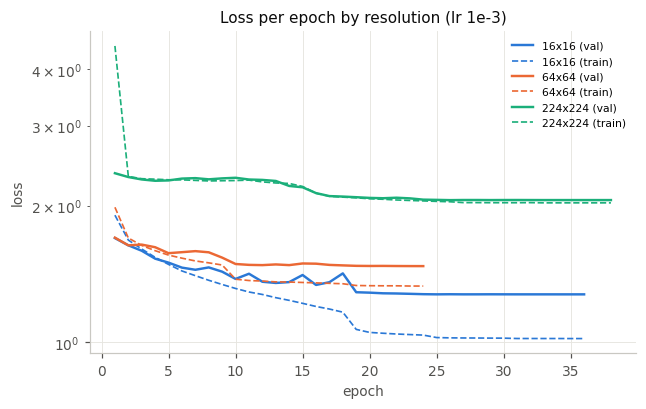

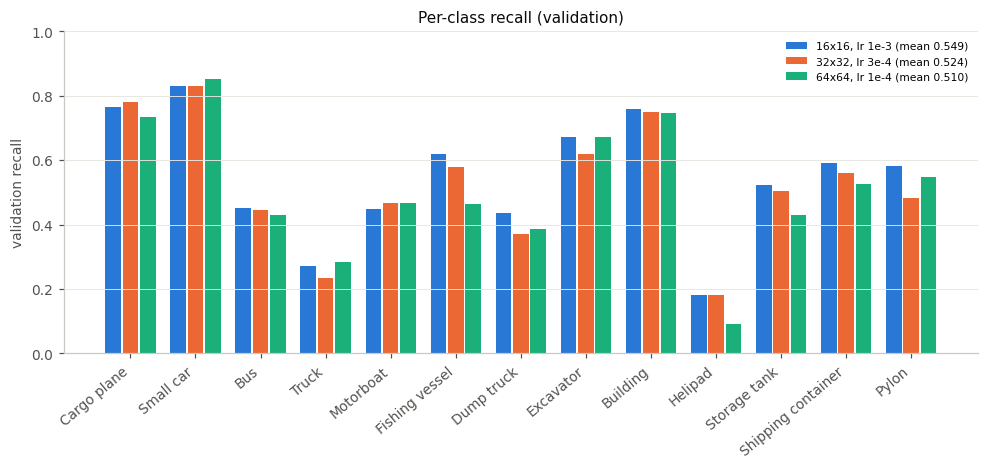

In [9]:
pu.plot_learning_curves(['EXP-005_r16', 'EXP-005_r64', 'EXP-005_r224'], 'loss', labels=['16x16', '64x64', '224x224'],
                        name='phase2_learning_curves_by_resolution', title='Loss per epoch by resolution (lr 1e-3)');
pu.plot_per_class_recall(['EXP-005_r16', 'EXP-005_r32_lr3e-4', 'EXP-005_r64_lr1e-4'], labels=['16x16, lr 1e-3', '32x32, lr 3e-4', '64x64, lr 1e-4'],
                         name='phase2_per_class_recall');

**Interpretation.** At lr 1e-3 the mean recall falls monotonically from 16×16 (0.549) to 224×224 (0.129), and the
*train* metric falls with it: at 224 the loss is stuck at ≈ 2.28 from epoch 2 (about the entropy of the class
frequencies) and accuracy at ≈ 0.21, i.e. the network collapsed to the class prior, most likely because the first Adam
steps over 150 528 inputs drove most ReLU units dead. That is underfitting caused by the optimisation, not overfitting.
With Adam each weight moves ≈ lr per step, so a pre-activation moves ≈ lr · Σ|xᵢ|, which grows with the number of
inputs: the best lr drops ≈ 3× each time the side doubles (16 → 1e-3, 32 → 3e-4, 64 → 1e-4). Compared at its own best
lr, **16×16 still wins** (0.549 vs 0.524 for 32×32 and 0.510 for 64×64), with the smallest model (200 k parameters) and
the fastest epochs; 8×8 loses detail (0.499). The train-validation gap is moderate (≈ 6 pp of mean recall at 16×16).

| Tried | Best | Kept for next phase |
|---|---|---|
| 8, 16, 24, 32, 48, 64, 112, 224 at lr 1e-3; 16/32/64 at 3 lr each | 16×16 at lr 1e-3: mean recall 0.549, val acc 0.600 | **16×16**, lr 1e-3 (second candidate: 32×32 at lr 3e-4, to re-check in phase 9) |

## Phase 3: depth and width (EXP-006)

16×16 input, lr 1e-3, everything else as in phase 2; only the hidden layers change: one layer of 64–1024 units, two
layers, three-layer funnels and a narrow-deep 256-256-256-256 (same parameter budget as one layer of 512).

In [10]:
df3 = pu.expand_config(pu.load_results('EXP-006'))
df3['inactive_units'] = [pu.load_history(r)['val'].get('inactive_units') for r in df3['id']]
table(df3)
display(df3[['id', 'params', 'gap_acc', 'gap', 'inactive_units']].style.format(precision=3).hide(axis='index'))

id,change,params,actual_epochs,best_epoch,train_acc,val_acc,train_mean_recall,mean_recall,min_recall,val_loss,s_per_epoch
EXP-006_h64,hidden 64,50061,30,20,0.573,0.526,0.507,0.468,0.091,1.422,7.940
EXP-006_h128,hidden 128,100109,30,20,0.611,0.569,0.558,0.514,0.182,1.317,7.270
EXP-006_h256,hidden 256,200205,36,26,0.661,0.600,0.609,0.549,0.182,1.275,6.850
EXP-006_h512,hidden 512,400397,30,20,0.671,0.595,0.629,0.543,0.182,1.260,6.950
EXP-006_h1024,hidden 1024,800781,31,21,0.698,0.602,0.659,0.562,0.272,1.246,7.100
EXP-006_h256-128,hidden 256-128,231437,39,29,0.717,0.599,0.674,0.565,0.244,1.253,7.890
EXP-006_h512-128,hidden 512-128,461069,33,23,0.723,0.605,0.684,0.560,0.182,1.255,7.950
EXP-006_h512-256,hidden 512-256,528397,24,14,0.649,0.590,0.602,0.548,0.182,1.262,8.010
EXP-006_h1024-256,hidden 1024-256,1053197,37,27,0.755,0.610,0.716,0.561,0.182,1.265,8.790
EXP-006_h512-256-128,hidden 512-256-128,559629,38,28,0.789,0.603,0.762,0.568,0.312,1.322,9.210


id,params,gap_acc,gap,inactive_units
EXP-006_h64,50061,0.047,0.040,0.312
EXP-006_h128,100109,0.042,0.044,0.312
EXP-006_h256,200205,0.061,0.060,0.281
EXP-006_h512,400397,0.076,0.086,0.268
EXP-006_h1024,800781,0.096,0.097,0.247
EXP-006_h256-128,231437,0.118,0.109,0.234
EXP-006_h512-128,461069,0.119,0.124,0.229
EXP-006_h512-256,528397,0.059,0.054,0.201
EXP-006_h1024-256,1053197,0.145,0.155,0.246
EXP-006_h512-256-128,559629,0.186,0.194,0.250


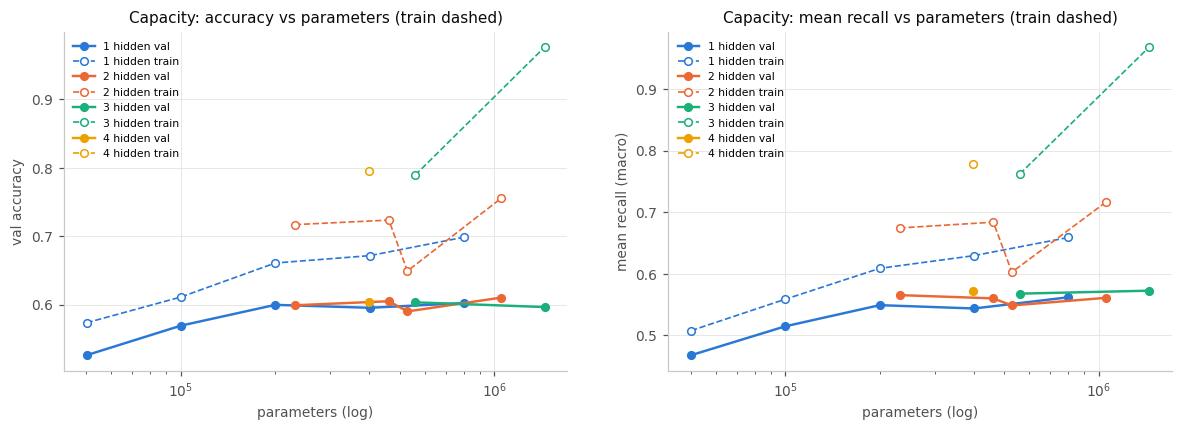

In [11]:
fig, axes = pu.plt.subplots(1, 2, figsize=(13, 4))
pu.plot_capacity(df3, metric='val_acc', ax=axes[0], title='Capacity: accuracy vs parameters (train dashed)')
pu.plot_capacity(df3, metric='mean_recall', ax=axes[1], title='Capacity: mean recall vs parameters (train dashed)')
pu._save(fig, 'phase3_capacity_vs_params');

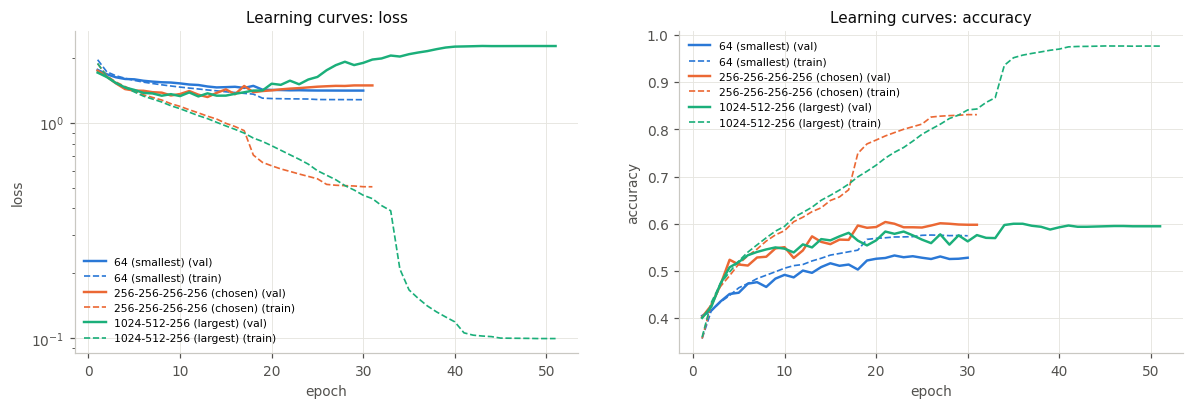

In [12]:
runs = ['EXP-006_h64', 'EXP-006_h256-256-256-256', 'EXP-006_h1024-512-256']
labels = ['64 (smallest)', '256-256-256-256 (chosen)', '1024-512-256 (largest)']
fig, axes = pu.plt.subplots(1, 2, figsize=(13, 3.8))
pu.plot_learning_curves(runs, 'loss', labels=labels, ax=axes[0])
pu.plot_learning_curves(runs, 'accuracy', labels=labels, ax=axes[1], logy=False)
pu._save(fig, 'phase3_learning_curves_small_chosen_large');

**Interpretation.** With one hidden layer, validation improves with width up to ~256 units and then flattens
(0.549 → 0.562 from 256 to 1024 units). Adding layers lifts the plateau to ~0.56–0.57, but above ~200 k parameters every
architecture lands within ~1 pp (not conclusive with a single seed) while the *train* metric keeps rising: from 0.66 (one
layer of 256) to 0.98 accuracy for 1024-512-256, i.e. the extra capacity is spent memorising the training set — the
transition from the "good fit" region to overfitting, which phase 6 has to address. At the same budget (~400 k
parameters) the narrow-deep 256-256-256-256 beats one layer of 512 (0.572 vs 0.543): depth helps more than width here.
Between 20 % and 34 % of the first-layer ReLU units are dead in every architecture — something phase 4 can test.

| Tried | Best | Kept for next phase |
|---|---|---|
| 12 architectures, 1–4 hidden layers, 50 k–1.45 M parameters | 1024-512-256 and 256-256-256-256: mean recall 0.572 | **256-256-256-256** (398 k params): ties the best with 3.6× fewer parameters, much smaller train-val gap (train acc 0.80 vs 0.98) and the best min recall (0.294) |

## Phase 4: activation functions (EXP-007)

Phase-3 network (16×16, 256-256-256-256), only the hidden activation changes, each with its recommended initialiser:
ReLU / LeakyReLU / ELU / GELU with `he_normal`, SELU with `lecun_normal`, tanh with `glorot_uniform`. The ReLU point is
the phase-3 winner itself. "Inactive units" = first-hidden-layer units whose pre-activation is ≤ 0 for every validation
image (for ReLU these are dead: they receive no gradient).

In [13]:
df4 = pu.expand_config(pd.concat([pu.load_results().query("id == 'EXP-006_h256-256-256-256'"), pu.load_results('EXP-007')]))
df4['act'] = ['relu' if a == 'relu' else r.split('_')[-1] for a, r in zip(df4['activation'], df4['id'])]
df4['inactive_units'] = [pu.load_history(r)['val'].get('inactive_units') for r in df4['id']]
table(df4)
display(df4[['act', 'inactive_units', 'gap_acc']].style.format(precision=3).hide(axis='index'))

id,change,params,actual_epochs,best_epoch,train_acc,val_acc,train_mean_recall,mean_recall,min_recall,val_loss,s_per_epoch
EXP-006_h256-256-256-256,hidden 256-256-256-256,397581,31,21,0.796,0.604,0.777,0.572,0.294,1.431,10.710
EXP-007_leaky0.1,activation leaky0.1,397581,29,19,0.717,0.596,0.676,0.544,0.182,1.253,10.580
EXP-007_leaky0.3,activation leaky0.3,397581,40,30,0.819,0.635,0.813,0.591,0.273,1.218,10.580
EXP-007_elu,activation elu,397581,37,27,0.969,0.595,0.967,0.561,0.344,2.147,10.690
EXP-007_gelu,activation gelu,397581,42,32,0.999,0.601,0.999,0.583,0.344,2.638,11.370
EXP-007_selu,activation selu,397581,38,28,0.923,0.601,0.923,0.569,0.273,1.732,10.480
EXP-007_tanh,activation tanh,397581,30,20,0.764,0.574,0.726,0.526,0.182,1.314,10.830
EXP-007_leaky0.3_seed2,"activation leaky0.3, seed 2",397581,36,26,0.751,0.622,0.732,0.584,0.344,1.187,11.920
EXP-007_leaky0.3_seed3,"activation leaky0.3, seed 3",397581,44,34,0.823,0.621,0.814,0.586,0.330,1.220,10.270


act,inactive_units,gap_acc
relu,0.336,0.192
leaky0.1,0.004,0.121
leaky0.3,0.000,0.184
elu,0.000,0.375
gelu,0.059,0.398
selu,0.000,0.322
tanh,0.012,0.190
seed2,0.000,0.129
seed3,0.000,0.202


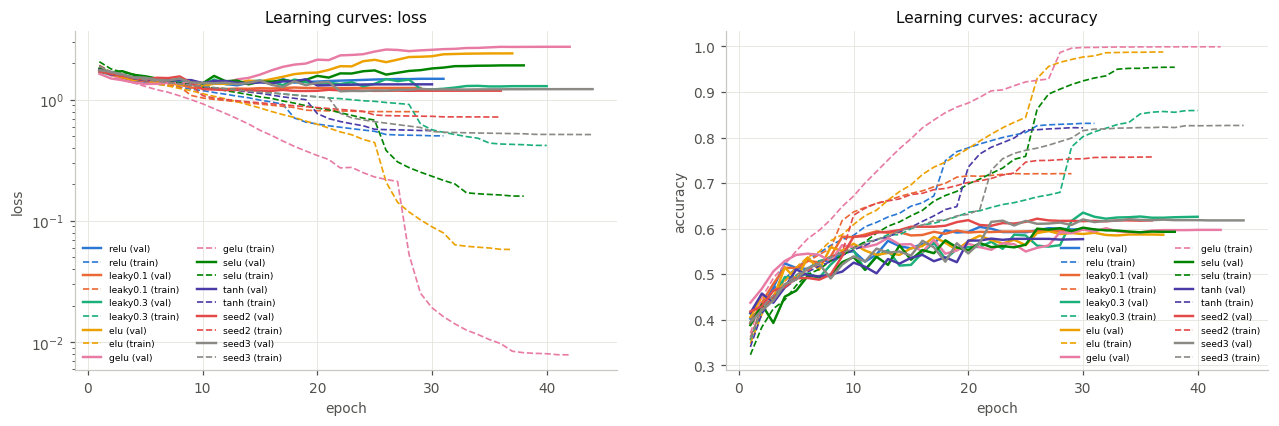

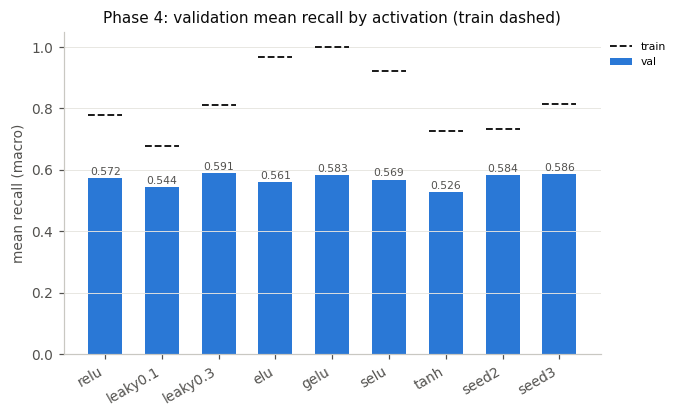

In [14]:
runs, labels = list(df4['id']), list(df4['act'])
fig, axes = pu.plt.subplots(1, 2, figsize=(14, 4))
pu.plot_learning_curves(runs, 'loss', labels=labels, ax=axes[0])
pu.plot_learning_curves(runs, 'accuracy', labels=labels, ax=axes[1], logy=False)
for ax in axes:
    ax.legend(fontsize=6, ncol=2)
pu._save(fig, 'phase4_learning_curves_by_activation')
pu.plot_bars(df4.assign(label=labels), 'mean_recall', label='label', name='phase4_mean_recall_by_activation',
             title='Phase 4: validation mean recall by activation (train dashed)');

**Interpretation.** 34 % of the ReLU units of the first layer are dead; every alternative brings that to ≈ 0
(GELU 6 %), and no activation shows a loss that fails to go down at the start. The best is **LeakyReLU with α = 0.3**
(mean recall 0.591, val acc 0.635, both the best of the phase). GELU (0.583), ELU and SELU fit the training set almost
perfectly (train accuracy 0.92–1.00) without gaining on validation: smoother activations make it easier to memorise.
tanh is the worst (0.526), as expected for a saturating activation. LeakyReLU with α = 0.1 is *below* ReLU even though it
also removes the dead units, so part of these 1–2 pp differences is single-seed noise; the advantage of α = 0.3 should
not be over-read.

| Tried | Best | Kept for next phase |
|---|---|---|
| ReLU, LeakyReLU 0.1 / 0.3, ELU, GELU, SELU, tanh | LeakyReLU α = 0.3: mean recall 0.591, val acc 0.635 | **LeakyReLU α = 0.3** with `he_normal` |

## Phase 5: optimiser and its hyperparameters (EXP-008 → EXP-012)

Phase-4 network (16×16, 256-256-256-256, LeakyReLU 0.3). As the plan asks, phase 5 explores with **short runs (≤ 20
epochs)**, fixing the best of each step before the next one. The reference is therefore the phase-4 configuration with
20 epochs (`EXP-008_adam_lr1e-3`, mean recall 0.518), not EXP-007 (0.591 with up to 60 epochs).

### 5.1 Learning rate (EXP-008)

id,change,params,actual_epochs,best_epoch,train_acc,val_acc,train_mean_recall,mean_recall,min_recall,val_loss,s_per_epoch
EXP-008_adam_lr1e-4,Adam lr 1e-4,397581,20,20,0.657,0.581,0.605,0.527,0.182,1.250,10.540
EXP-008_adam_lr3e-4,Adam lr 3e-4,397581,20,16,0.687,0.570,0.660,0.535,0.226,1.280,10.540
EXP-008_adam_lr1e-3,Adam lr 1e-3,397581,20,20,0.665,0.559,0.652,0.518,0.222,1.347,10.380
EXP-008_adam_lr3e-3,Adam lr 3e-3,397581,20,20,0.592,0.539,0.535,0.480,0.000,1.381,10.690
EXP-008_adam_lr1e-2,Adam lr 1e-2,397581,20,17,0.642,0.578,0.593,0.520,0.182,1.311,10.550
EXP-008_sgdm_lr1e-3,SGD momentum 0.9 lr 1e-3,397581,20,20,0.571,0.533,0.498,0.455,0.000,1.397,7.480
EXP-008_sgdm_lr1e-2,SGD momentum 0.9 lr 1e-2,397581,20,20,0.773,0.609,0.747,0.582,0.364,1.188,7.410
EXP-008_sgdm_lr1e-1,SGD momentum 0.9 lr 1e-1,397581,20,20,0.622,0.547,0.589,0.512,0.182,1.335,7.570


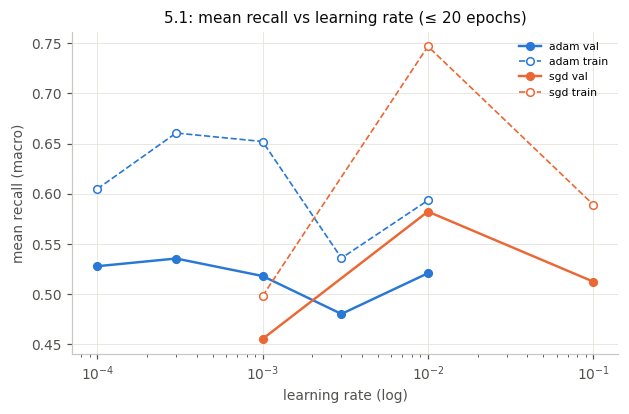

In [15]:
df51 = pu.expand_config(pu.load_results('EXP-008'))
table(df51)
pu.plot_sweep(df51, 'lr', 'mean_recall', logx=True, group='optimizer', name='phase5_1_metric_vs_lr',
              title='5.1: mean recall vs learning rate (≤ 20 epochs)', xlabel='learning rate (log)');

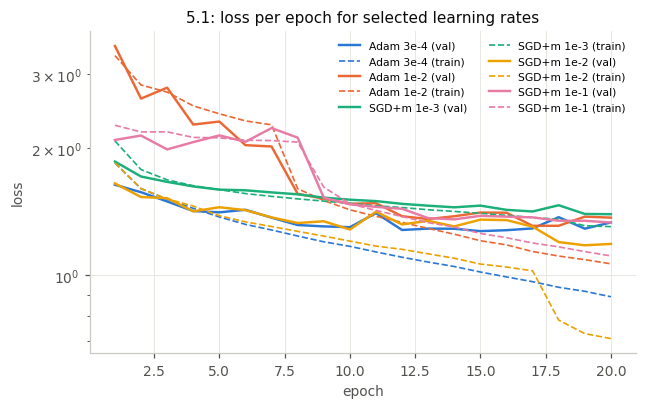

In [16]:
pu.plot_learning_curves(['EXP-008_adam_lr3e-4', 'EXP-008_adam_lr1e-2', 'EXP-008_sgdm_lr1e-3', 'EXP-008_sgdm_lr1e-2', 'EXP-008_sgdm_lr1e-1'], 'loss',
                        labels=['Adam 3e-4', 'Adam 1e-2', 'SGD+m 1e-3', 'SGD+m 1e-2', 'SGD+m 1e-1'], name='phase5_1_learning_curves',
                        title='5.1: loss per epoch for selected learning rates');

**Interpretation.** With this budget Adam is almost insensitive to the learning rate between 1e-4 and 1e-2 (0.52–0.535,
within single-seed noise; only 3e-3 drops to 0.48), and it does not diverge even at 1e-2 (clipnorm and AMSGrad).
SGD with momentum 0.9 is sharply peaked: too slow at 1e-3 (0.455), unstable at 1e-1 (0.512) and clearly the best of the
phase at **1e-2 (0.582, val acc 0.609, min recall 0.364)**, with 30 % faster epochs than Adam. Several runs peak at the
last epoch, so this sweep also measures convergence speed; the winning configuration is re-checked with the full budget
at the end of phase 5.

| Tried | Best | Kept |
|---|---|---|
| Adam lr 1e-4…1e-2, SGD+momentum 0.9 lr 1e-3…1e-1 | SGD+m lr 1e-2: 0.582 (Adam best: 3e-4, 0.535) | SGD lr 1e-2 for the momentum sweep; Adam lr 3e-4 for its betas |

### 5.2 Momentum and optimiser comparison (EXP-009)

SGD at lr 1e-2 with momentum 0–0.99 (with and without Nesterov), Adam at lr 3e-4 with different β₁ / β₂, RMSprop at four
learning rates. The two finalists were then repeated with seeds 2 and 3 to measure the run-to-run noise.

id,change,params,actual_epochs,best_epoch,train_acc,val_acc,train_mean_recall,mean_recall,min_recall,val_loss,s_per_epoch
EXP-009_sgd_m0.0,SGD lr 1e-2 momentum 0.0,397581,20,14,0.542,0.519,0.485,0.459,0.000,1.459,6.580
EXP-009_sgd_m0.5,SGD lr 1e-2 momentum 0.5,397581,20,20,0.642,0.576,0.588,0.524,0.182,1.255,7.660
EXP-009_sgd_m0.95,SGD lr 1e-2 momentum 0.95,397581,20,20,0.614,0.537,0.602,0.508,0.182,1.436,7.340
EXP-009_sgd_m0.99,SGD lr 1e-2 momentum 0.99,397581,20,20,0.572,0.520,0.514,0.451,0.182,1.456,7.720
EXP-009_sgd_m0.5_nesterov,SGD lr 1e-2 momentum 0.5 Nesterov,397581,20,20,0.645,0.573,0.592,0.526,0.182,1.261,7.530
EXP-009_sgd_m0.9_nesterov,SGD lr 1e-2 momentum 0.9 Nesterov,397581,20,18,0.695,0.584,0.681,0.559,0.249,1.314,7.720
EXP-009_sgd_m0.95_nesterov,SGD lr 1e-2 momentum 0.95 Nesterov,397581,20,14,0.681,0.601,0.652,0.572,0.182,1.204,7.690
EXP-009_sgd_m0.99_nesterov,SGD lr 1e-2 momentum 0.99 Nesterov,397581,20,20,0.611,0.553,0.570,0.506,0.182,1.369,7.600
EXP-009_adam_b1_0.8,Adam beta_1 0.8,397581,20,17,0.703,0.595,0.661,0.553,0.213,1.250,10.480
EXP-009_adam_b1_0.95,Adam beta_1 0.95,397581,20,20,0.761,0.614,0.729,0.569,0.273,1.181,10.570


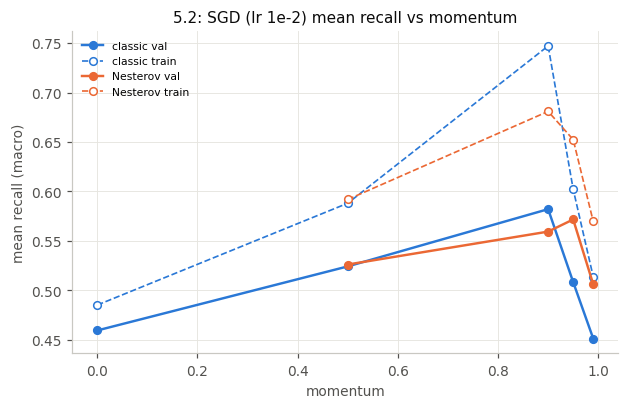

In [17]:
df52 = pu.expand_config(pu.load_results('EXP-009'))
sgd = pu.expand_config(pd.concat([pu.load_results().query("id == 'EXP-008_sgdm_lr1e-2'"), pu.load_results('EXP-009')]))
sgd = sgd[(sgd['optimizer'] == 'sgd') & (sgd['seed'] == 1)].copy()
cfg = [pu.json.loads(c)['optimizer'] for c in sgd['config']]
sgd['momentum'] = [c['momentum'] for c in cfg]
sgd['update'] = ['Nesterov' if c['nesterov'] else 'classic' for c in cfg]
table(df52)
pu.plot_sweep(sgd, 'momentum', 'mean_recall', group='update', name='phase5_2_metric_vs_momentum',
              title='5.2: SGD (lr 1e-2) mean recall vs momentum', xlabel='momentum');

variant,n_seeds,mean_recall_mean,mean_recall_std,val_acc_mean,val_acc_std,min_recall_mean,min_recall_std,train_mean_recall_mean,train_mean_recall_std,train_acc_mean,train_acc_std
SGD m0.9 lr1e-2,3,0.565,0.018,0.608,0.014,0.273,0.091,0.687,0.055,0.724,0.046
Adam b1 0.95 lr3e-4,3,0.571,0.009,0.608,0.019,0.257,0.027,0.705,0.043,0.735,0.042


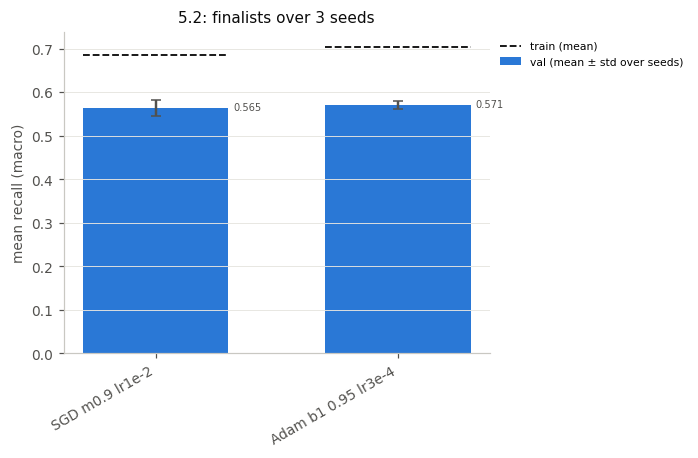

In [18]:
fin = pu.expand_config(pu.load_results().query("id.str.startswith('EXP-008_sgdm_lr1e-2') or id.str.startswith('EXP-009_sgd_m0.9_seed') or id.str.startswith('EXP-009_adam_b1_0.95')", engine='python'))
fin['variant'] = ['SGD m0.9 lr1e-2' if o == 'sgd' else 'Adam b1 0.95 lr3e-4' for o in fin['optimizer']]
s52 = pu.seed_summary(fin)
display(s52.style.format(precision=3).hide(axis='index'))
pu.plot_seed_bars(s52, name='phase5_2_finalists_3_seeds', title='5.2: finalists over 3 seeds');

**Interpretation.** Momentum matters a lot for SGD (0.459 without, 0.582 with 0.9), and too much momentum (0.99, an
effective step lr/(1−m) = 1) degrades it again. Nesterov gives no consistent gain. The β variations of Adam and the
RMSprop learning rates move the result by 2–3 pp in non-monotonic ways — and the 3-seed repetition shows why: **the
run-to-run noise is σ ≈ 1–2 pp**, so single-seed differences below ~3 pp (in this phase and in phases 3–4) are not
conclusive. The two finalists tie (SGD+m 0.565 ± 0.018, Adam β₁ 0.95 0.571 ± 0.009). Adam is kept for its lower seed
variance and its flat response to the lr (useful for 5.3); SGD would be 30 % faster per epoch.

| Tried | Best | Kept |
|---|---|---|
| SGD momentum 0–0.99 ± Nesterov, Adam β₁/β₂, RMSprop lr | tie: SGD+m 0.9 (0.565 ± 0.018) vs Adam β₁ 0.95 (0.571 ± 0.009) | **Adam, lr 3e-4, β₁ 0.95** |

### 5.3 Batch size (EXP-010)

id,change,params,actual_epochs,best_epoch,train_acc,val_acc,train_mean_recall,mean_recall,min_recall,val_loss,s_per_epoch
EXP-009_adam_b1_0.95,Adam beta_1 0.95,397581,20,20,0.761,0.614,0.729,0.569,0.273,1.181,10.570
EXP-010_bs32_sqrt,"batch 32, lr 0.00042 (sqrt rule)",397581,20,20,0.723,0.578,0.702,0.552,0.273,1.255,4.450
EXP-010_bs64_sqrt,"batch 64, lr 0.0006 (sqrt rule)",397581,20,20,0.750,0.614,0.717,0.571,0.253,1.160,2.520
EXP-010_bs128_sqrt,"batch 128, lr 0.00085 (sqrt rule)",397581,20,19,0.723,0.611,0.674,0.566,0.273,1.173,1.440
EXP-010_bs256_sqrt,"batch 256, lr 0.0012 (sqrt rule)",397581,20,20,0.718,0.609,0.682,0.574,0.240,1.184,0.680
EXP-010_bs64_linear,"batch 64, lr 0.0012 (linear rule)",397581,20,17,0.660,0.582,0.649,0.563,0.113,1.263,2.800
EXP-010_bs256_linear,"batch 256, lr 0.0048 (linear rule)",397581,20,20,0.661,0.591,0.642,0.565,0.258,1.199,0.660


id,batch_size,lr,s_per_epoch,time_to_0.58_s
EXP-009_adam_b1_0.95,16,0.0003,10.5700,159.2808
EXP-010_bs32_sqrt,32,0.0004,4.4500,68.2805
EXP-010_bs64_sqrt,64,0.0006,2.5200,34.1463
EXP-010_bs128_sqrt,128,0.0008,1.4400,26.3355
EXP-010_bs256_sqrt,256,0.0012,0.6800,13.5208
EXP-010_bs64_linear,64,0.0012,2.8000,45.1860
EXP-010_bs256_linear,256,0.0048,0.6600,11.8419


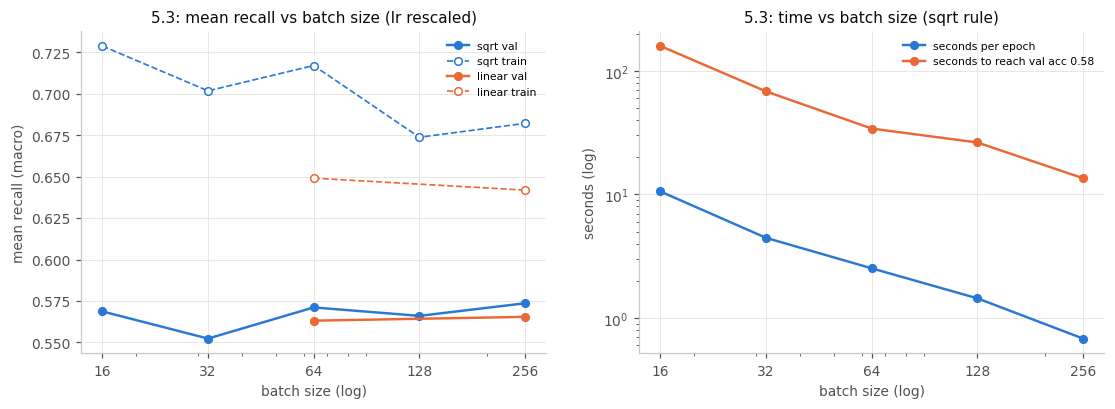

In [19]:
import numpy as np
df53 = pu.expand_config(pd.concat([pu.load_results().query("id == 'EXP-009_adam_b1_0.95'"), pu.load_results('EXP-010')]))
df53 = df53[(df53['seed'] == 1) & ~df53['id'].str.contains('60ep')].copy()
df53['rule'] = ['sqrt' if ('sqrt' in i or 'EXP-009' in i) else 'linear' for i in df53['id']]
def time_to(rid, target=0.58):
    h = pu.load_history(rid)['history']; va = np.array(h['val_accuracy']); t = np.cumsum(h['epoch_time'])
    return float(t[np.argmax(va >= target)]) if (va >= target).any() else np.nan
df53['time_to_0.58_s'] = [time_to(r) for r in df53['id']]
table(df53)
display(df53[['id', 'batch_size', 'lr', 's_per_epoch', 'time_to_0.58_s']].style.format(precision=4).hide(axis='index'))
fig, axes = pu.plt.subplots(1, 2, figsize=(12, 3.8))
pu.plot_sweep(df53, 'batch_size', 'mean_recall', logx=True, group='rule', ax=axes[0], title='5.3: mean recall vs batch size (lr rescaled)', xlabel='batch size (log)')
sq = df53[df53['rule'] == 'sqrt'].sort_values('batch_size')
axes[1].plot(sq['batch_size'], sq['s_per_epoch'], marker='o', color=pu.PALETTE[0], label='seconds per epoch')
axes[1].plot(sq['batch_size'], sq['time_to_0.58_s'], marker='o', color=pu.PALETTE[1], label='seconds to reach val acc 0.58')
axes[1].set_xscale('log'); axes[1].set_yscale('log'); axes[1].set_xlabel('batch size (log)'); axes[1].set_ylabel('seconds (log)')
axes[1].set_title('5.3: time vs batch size (sqrt rule)'); axes[1].legend(fontsize=7)
for ax in axes:
    ax.set_xticks(sorted(df53['batch_size'].unique())); ax.set_xticklabels(sorted(df53['batch_size'].unique()))
pu._save(fig, 'phase5_3_batch_size');

**Interpretation.** Every batch size lands within the seed noise (0.552–0.574), with either lr rule, but the cost
falls dramatically: one epoch takes 10.6 s at batch 16 and 0.7 s at batch 256 (15× faster; at batch 16 the GPU is
dominated by per-step overhead), and val accuracy 0.58 is reached in 14 s instead of 159 s. **Batch 256 with lr 1.2e-3
(square-root rule)** is kept. Runs now take under a minute, so from here on the short exploration budget is dropped
(back to 60 epochs, EarlyStopping 10) and the decisions use **3 seeds**. With 60 epochs the new base gives the same
result (best epoch 20, stopped at 30): **0.578 ± 0.007** over 3 seeds.

### 5.4 Learning-rate schedule (EXP-011)

id,change,params,actual_epochs,best_epoch,train_acc,val_acc,train_mean_recall,mean_recall,min_recall,val_loss,s_per_epoch
EXP-010_bs256_sqrt_60ep,"batch 256, lr 0.0012, 60 epochs (new base)",397581,30,20,0.718,0.609,0.682,0.574,0.240,1.184,0.580
EXP-011_cosine,cosine decay,397581,38,28,0.757,0.594,0.739,0.570,0.217,1.291,0.650
EXP-011_exponential,exponential decay 0.9/epoch,397581,42,32,0.696,0.589,0.649,0.554,0.262,1.219,0.630
EXP-011_warmup_cosine_2x,"warmup 3 ep + cosine, lr x2",397581,46,36,0.844,0.604,0.844,0.581,0.317,1.404,0.630
EXP-011_warmup_plateau_2x,"warmup 3 ep + plateau, lr x2",397581,42,32,0.810,0.619,0.805,0.594,0.344,1.206,0.570
EXP-011_plateau_2x,"plateau, lr x2 (no warmup)",397581,32,22,0.723,0.615,0.702,0.590,0.267,1.171,0.640
EXP-010_bs256_sqrt_60ep_seed2,"batch 256, lr 0.0012, 60 epochs, seed 2",397581,41,31,0.772,0.618,0.756,0.574,0.273,1.176,0.600
EXP-011_warmup_plateau_2x_seed2,"warmup 3 ep + plateau, lr x2, seed 2",397581,29,19,0.676,0.592,0.624,0.553,0.226,1.217,0.700
EXP-010_bs256_sqrt_60ep_seed3,"batch 256, lr 0.0012, 60 epochs, seed 3",397581,42,32,0.777,0.620,0.749,0.585,0.299,1.181,0.720
EXP-011_warmup_plateau_2x_seed3,"warmup 3 ep + plateau, lr x2, seed 3",397581,44,34,0.773,0.627,0.755,0.605,0.317,1.162,0.740


variant,n_seeds,mean_recall_mean,mean_recall_std,val_acc_mean,val_acc_std,min_recall_mean,min_recall_std,train_mean_recall_mean,train_mean_recall_std,train_acc_mean,train_acc_std
EXP-010_bs256_sqrt_60ep,3,0.578,0.007,0.616,0.006,0.270,0.029,0.729,0.041,0.756,0.033
EXP-011_cosine,1,0.570,nan,0.594,nan,0.217,nan,0.739,nan,0.757,nan
EXP-011_exponential,1,0.554,nan,0.589,nan,0.262,nan,0.649,nan,0.696,nan
EXP-011_warmup_cosine_2x,1,0.581,nan,0.604,nan,0.317,nan,0.844,nan,0.844,nan
EXP-011_warmup_plateau_2x,3,0.584,0.028,0.613,0.018,0.296,0.062,0.728,0.093,0.753,0.069
EXP-011_plateau_2x,1,0.590,nan,0.615,nan,0.267,nan,0.702,nan,0.723,nan


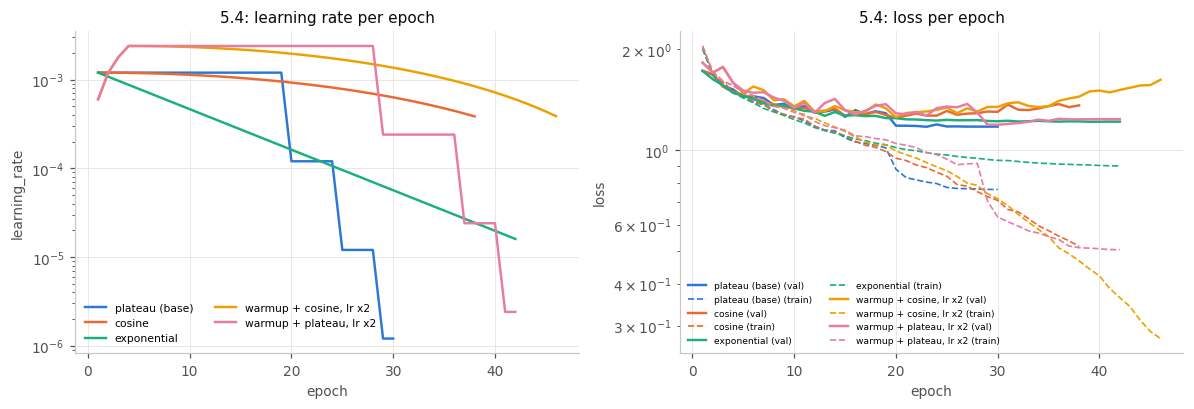

In [20]:
df54 = pu.expand_config(pu.load_results().query("id.str.startswith('EXP-010_bs256_sqrt_60ep') or exp_id == 'EXP-011'", engine='python'))
table(df54)
s54 = pu.seed_summary(df54)
display(s54.style.format(precision=3).hide(axis='index'))
runs = ['EXP-010_bs256_sqrt_60ep', 'EXP-011_cosine', 'EXP-011_exponential', 'EXP-011_warmup_cosine_2x', 'EXP-011_warmup_plateau_2x']
labels = ['plateau (base)', 'cosine', 'exponential', 'warmup + cosine, lr x2', 'warmup + plateau, lr x2']
fig, axes = pu.plt.subplots(1, 2, figsize=(13, 3.8))
pu.plot_learning_curves(runs, 'learning_rate', labels=labels, ax=axes[0], title='5.4: learning rate per epoch')
pu.plot_learning_curves(runs, 'loss', labels=labels, ax=axes[1], title='5.4: loss per epoch')
axes[1].legend(fontsize=6, ncol=2)
pu._save(fig, 'phase5_4_schedules');

**Interpretation.** With a single seed, warmup + ReduceLROnPlateau at twice the lr looked best (0.594), but separating
the factors (2× lr without warmup: 0.590) and repeating with 3 seeds shows a tie with the base (0.584 ± 0.028 vs
0.578 ± 0.007, four times the variance). Cosine (0.570) and exponential decay (0.554) are not better. **The base is
kept** (ReduceLROnPlateau, lr 1.2e-3, no warmup): simplest and most stable.

### 5.5 Other optimiser settings (EXP-012)

variant,n_seeds,mean_recall_mean,mean_recall_std,val_acc_mean,val_acc_std,min_recall_mean,min_recall_std,train_mean_recall_mean,train_mean_recall_std,train_acc_mean,train_acc_std
"base (Adam, AMSGrad, clipnorm 1)",3,0.578,0.007,0.616,0.006,0.270,0.029,0.729,0.041,0.756,0.033
no_clipnorm,3,0.565,0.032,0.605,0.017,0.218,0.062,0.672,0.076,0.711,0.058
no_amsgrad,3,0.572,0.006,0.608,0.003,0.293,0.061,0.736,0.050,0.760,0.033
adamw_wd1e-4,3,0.565,0.017,0.606,0.011,0.266,0.011,0.700,0.040,0.734,0.030
adamw_wd1e-3,3,0.579,0.023,0.611,0.010,0.272,0.023,0.733,0.038,0.758,0.027
adamw_wd1e-2,3,0.566,0.010,0.606,0.008,0.255,0.017,0.683,0.011,0.722,0.013


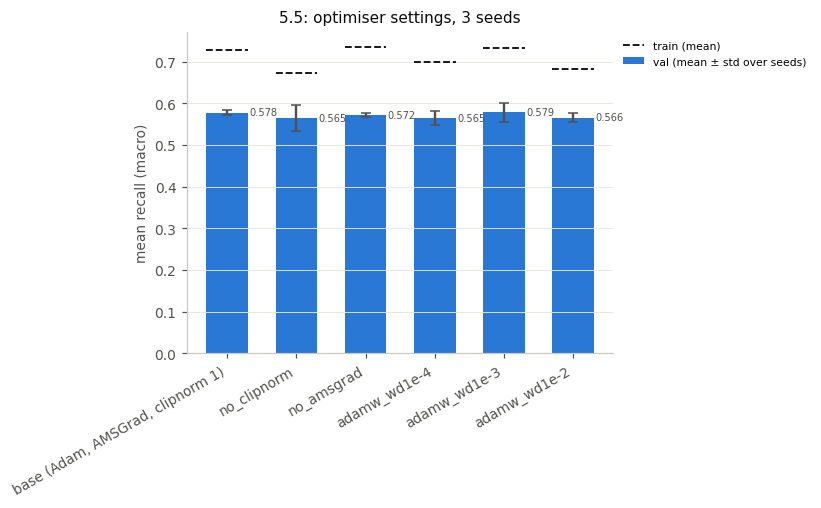

In [21]:
df55 = pu.expand_config(pu.load_results().query("id.str.startswith('EXP-010_bs256_sqrt_60ep') or exp_id == 'EXP-012'", engine='python'))
s55 = pu.seed_summary(df55)
s55['variant'] = s55['variant'].str.replace('EXP-010_bs256_sqrt_60ep', 'base (Adam, AMSGrad, clipnorm 1)').str.replace('EXP-012_', '')
display(s55.style.format(precision=3).hide(axis='index'))
pu.plot_seed_bars(s55, name='phase5_5_optimizer_settings', title='5.5: optimiser settings, 3 seeds');

**Interpretation.** Removing clipnorm (0.565 ± 0.032) or AMSGrad (0.572 ± 0.006), or switching to AdamW with
decoupled weight decay 1e-4 / 1e-3 / 1e-2 (0.565 / 0.579 / 0.566), changes nothing beyond the noise. The base is kept.

**End of phase 5.** The optimiser phase did not raise the metric — EXP-007 (Adam lr 1e-3, batch 16) gave 0.591 with one
seed and the phase-5 base gives 0.578 ± 0.007 — but it made training **15× faster** and allowed every later decision
to use 3 seeds. The full-budget check of EXP-007 with 3 seeds is below.

| Step | Tried | Kept |
|---|---|---|
| 5.1 | Adam / SGD+m learning rates | SGD+m lr 1e-2 and Adam lr 3e-4 as candidates |
| 5.2 | momentum, Nesterov, Adam β, RMSprop | Adam lr 3e-4 β₁ 0.95 (tie with SGD+m, lower variance) |
| 5.3 | batch 16–256, sqrt / linear lr rule | batch 256, lr 1.2e-3 (same metric, 15× faster) |
| 5.4 | plateau, cosine, exponential, warmup | ReduceLROnPlateau, no warmup |
| 5.5 | clipnorm, AMSGrad, AdamW | unchanged |

In [22]:
chk = pu.expand_config(pu.load_results().query("id.str.startswith('EXP-007_leaky0.3') or id.str.startswith('EXP-010_bs256_sqrt_60ep')", engine='python'))
chk['variant'] = ['EXP-007 (Adam lr 1e-3, batch 16)' if i.startswith('EXP-007') else 'phase 5 (Adam lr 1.2e-3 b1 0.95, batch 256)' for i in chk['id']]
display(pu.seed_summary(chk).style.format(precision=3).hide(axis='index'))

variant,n_seeds,mean_recall_mean,mean_recall_std,val_acc_mean,val_acc_std,min_recall_mean,min_recall_std,train_mean_recall_mean,train_mean_recall_std,train_acc_mean,train_acc_std
"EXP-007 (Adam lr 1e-3, batch 16)",3,0.587,0.004,0.626,0.008,0.316,0.038,0.786,0.047,0.798,0.040
"phase 5 (Adam lr 1.2e-3 b1 0.95, batch 256)",3,0.578,0.007,0.616,0.006,0.270,0.029,0.729,0.041,0.756,0.033
